Multilayer Perceptron Evaluated on features of age, gender, race

In [12]:
%pip install datasets torch scikit-learn pandas matplotlib seaborn
import os
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, TensorDataset
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from datasets import load_dataset


ds = load_dataset("harvardairobotics/Harvard-GF", "default")


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
#df = ds['train'].to_pandas()
#pd.set_option('display.max_rows', None)
#print(df['age'].describe())
#df['age'].plot.hist(bins=20, edgecolor='black')
#plt.show()


In [14]:

df = ds['train'].to_pandas()
X = df[['age','gender','race']].copy()
y = df['glaucoma'].copy()

X['age'] = X['age'].astype(int)
X_encoded = pd.get_dummies(X, columns=['gender', 'race'], drop_first=True)
y_encoded = df['glaucoma'].map({"yes": 1, "no": 0}).astype(float)

X_train, X_temp, y_train, y_temp = train_test_split(X_encoded, y_encoded, test_size=0.2, random_state=42)
X_test, X_val, y_test, y_val = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42) # split 20% test in half into 10% test 10% validation

# Feature Scaling
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train) # baseline
X_test = scaler.transform(X_test)
X_val = scaler.transform(X_val)

X_train_tensor = torch.tensor(X_train.astype(float), dtype=torch.float32)
y_train_tensor = torch.tensor(y_train.to_numpy().astype(float), dtype=torch.float32)
X_test_tensor = torch.tensor(X_test.astype(float), dtype=torch.float32)
y_test_tensor = torch.tensor(y_test.to_numpy().astype(float), dtype=torch.float32)
X_val_tensor = torch.tensor(X_val.astype(float), dtype=torch.float32)
y_val_tensor = torch.tensor(y_val.to_numpy().astype(float), dtype=torch.float32)


print(f"Train size: {X_train_tensor.shape[0]}, Test Size: {X_test_tensor.shape[0]}, Val Size: {X_val_tensor.shape[0]}")



train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True) #todo add validation set
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)




Train size: 2640, Test Size: 330, Val Size: 330


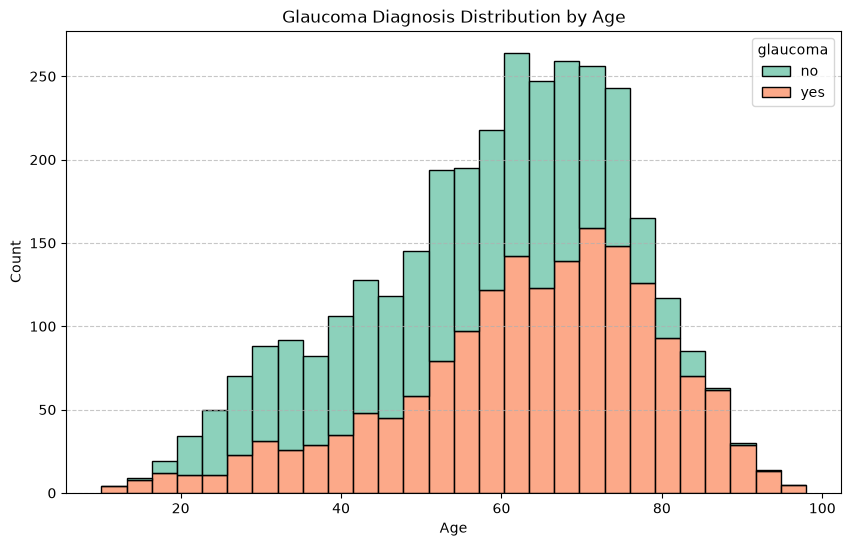

In [15]:
# Plot

import seaborn as sns
import matplotlib.pyplot as plt

plot_df = df[['age', 'glaucoma']].copy()

plt.figure(figsize = (10, 6))
sns.histplot(data=plot_df, x='age', hue='glaucoma', multiple='stack', palette='Set2')
plt.title('Glaucoma Diagnosis Distribution by Age')
plt.xlabel('Age')
plt.ylabel('Count')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

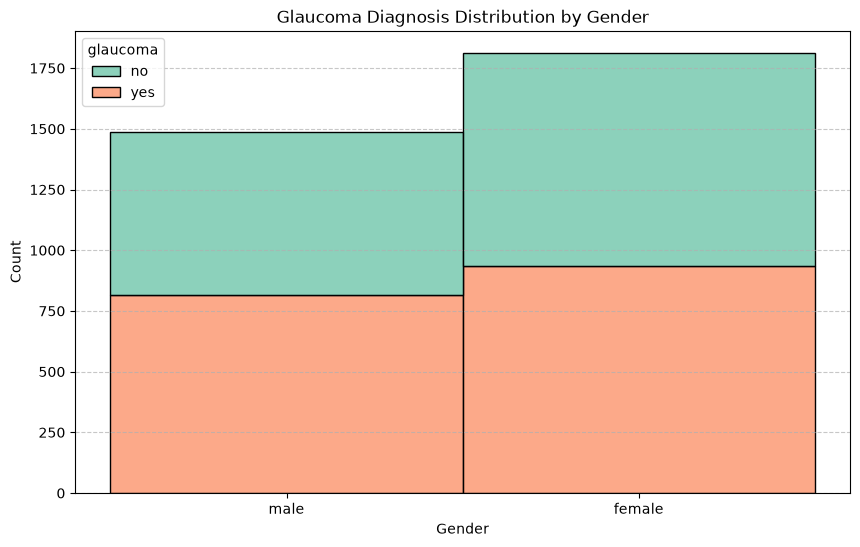

In [16]:
# Plot

import seaborn as sns
import matplotlib.pyplot as plt

plot_df = df[['gender', 'glaucoma']].copy()

plt.figure(figsize = (10, 6))
sns.histplot(data=plot_df, x='gender', hue='glaucoma', multiple='stack', palette='Set2')
plt.title('Glaucoma Diagnosis Distribution by Gender')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

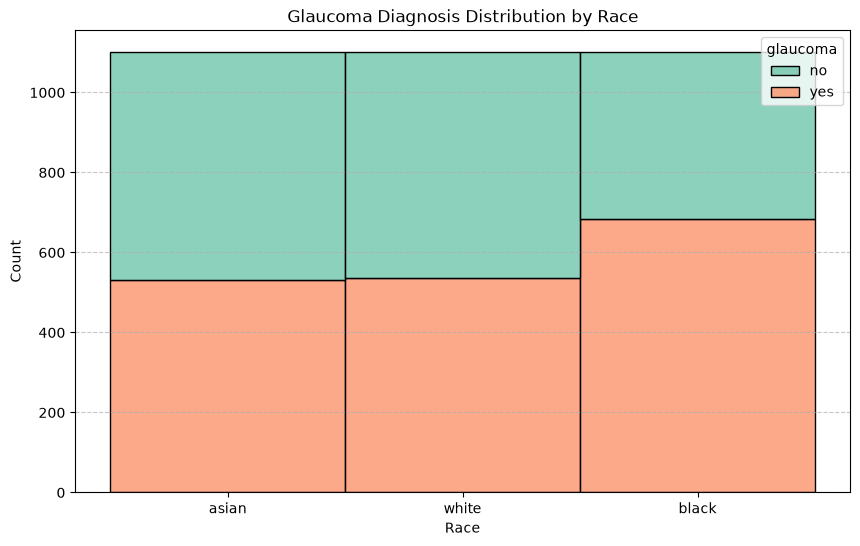

In [18]:
# Plot

import seaborn as sns
import matplotlib.pyplot as plt

plot_df = df[['race', 'glaucoma']].copy()

plt.figure(figsize = (10, 6))
sns.histplot(data=plot_df, x='race', hue='glaucoma', multiple='stack', palette='Set2')
plt.title('Glaucoma Diagnosis Distribution by Race')
plt.xlabel('Race')
plt.ylabel('Count')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [9]:
# define multi-layer perceptron

class MultiLayerPerceptron(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            # layer 1
            nn.Linear(4, 16),
            nn.ReLU(),
            nn.Dropout(0.2),
            
            # layer 2
            nn.Linear(16, 8),
            nn.ReLU(),
            
            #output layer (binary classification)
            nn.Linear(8, 2)
        )

    def forward(self, x):
        # flatten input?
        return self.network(x)
    
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = MultiLayerPerceptron().to(device)
print(model)

MultiLayerPerceptron(
  (network): Sequential(
    (0): Linear(in_features=4, out_features=16, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=16, out_features=8, bias=True)
    (4): ReLU()
    (5): Linear(in_features=8, out_features=2, bias=True)
  )
)


In [10]:
'''
# define training loop

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

def train(model, train_loader, criterion, optimizer, device, epochs):
    model.train()
    for epoch in range(epochs):
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels.long())
            loss.backward()
            optimizer.step()
        print(f"Epoch [{epoch+1}/{epochs}], Loss: {loss.item():.4f}")


train(model, train_loader, criterion, optimizer, device, epochs=100)
'''

'\n# define training loop\n\ncriterion = nn.CrossEntropyLoss()\noptimizer = optim.Adam(model.parameters(), lr=0.001)\n\ndef train(model, train_loader, criterion, optimizer, device, epochs):\n    model.train()\n    for epoch in range(epochs):\n        for inputs, labels in train_loader:\n            inputs, labels = inputs.to(device), labels.to(device)\n            optimizer.zero_grad()\n            outputs = model(inputs)\n            loss = criterion(outputs, labels.long())\n            loss.backward()\n            optimizer.step()\n        print(f"Epoch [{epoch+1}/{epochs}], Loss: {loss.item():.4f}")\n\n\ntrain(model, train_loader, criterion, optimizer, device, epochs=100)\n'

In [6]:
import torch
import torch.nn as nn

# Setup model, loss, optimizer, and data loaders
criterion = nn.CrossEntropyLoss() # or nn.MSELoss() for regression
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
epochs = 100
for epoch in range(epochs):
    # ==========================================
    # 1. TRAINING PHASE
    # ==========================================
    model.train()  # Enables dropout and batchnorm behaviors
    train_loss = 0.0
    
    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()         # Reset accumulated gradients
        predictions = model(X_batch)  # Forward pass
        loss = criterion(predictions, y_batch)
        loss.backward()               # Backward pass (compute gradients)
        optimizer.step()              # Update MLP weights
        
        train_loss += loss.item()
        
    # ==========================================
    # 2. VALIDATION PHASE
    # ==========================================
    model.eval()   # Disables dropout/batchnorm for evaluation
    val_loss = 0.0
    
    # Disable gradient tracking to save memory and speed up processing
    with torch.no_grad(): 
        for X_val, y_val in val_loader:
            val_predictions = model(X_val)
            v_loss = criterion(val_predictions, y_val)
            val_loss += v_loss.item()
            
    # Print metrics to monitor progress
    avg_train = train_loss / len(train_loader)
    avg_val = val_loss / len(val_loader)
    print(f"Epoch {epoch+1} | Train Loss: {avg_train:.4f} | Val Loss: {avg_val:.4f}")


RuntimeError: expected target dtype to be Long or Byte, but got Float

In [ ]:
def evaluate(model, test_loader, criterion, device):
    model.eval()
    total_loss = 0
    total_samples = 0
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels.long())
            total_loss += loss.item() * inputs.size(0)
            total_samples += inputs.size(0)
    return total_loss / total_samples

evaluate(model, test_loader, criterion, device)



0.624866738319397